In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import platform

# 그림 속 한글이 네모로 나오지 않게 (운영체제별 글꼴)
fonts = {"Windows": "Malgun Gothic",
         "Darwin": "AppleGothic"}
name = fonts.get(platform.system(), "NanumGothic")
plt.rcParams["font.family"] = name
plt.rcParams["axes.unicode_minus"] = False

In [2]:
df = pd.read_csv("sales_data.csv")

dates = ["order_date", "shipping_date", "delivery_date"]
for col in dates:
    df[col] = pd.to_datetime(df[col])

df.shape

(1030, 14)

In [3]:
before = len(df)
df = df.drop_duplicates()
print(before, "->", len(df))

1030 -> 1004


In [4]:
bad = df["quantity"] > 100
df.loc[bad, "quantity"] = (df.loc[bad, "total_sales"] / df.loc[bad, "unit_price"]).round().astype(int)
diff = (df["total_sales"] - df["quantity"] * df["unit_price"]).abs()
print("고친 줄 :", bad.sum(), " 수량 최대 :", df["quantity"].max(), " 총액 안 맞는 줄 :", (diff > 1).sum())

고친 줄 : 22  수량 최대 : 99  총액 안 맞는 줄 : 0


In [5]:
df["date_error"] = df["delivery_date"] < df["shipping_date"]
print(df["date_error"].value_counts())

df.to_csv("sales_clean.csv", index=False)
df.shape

date_error
False    857
True     147
Name: count, dtype: int64


(1004, 15)

## 단계 ⑤ 배송 기간 (도착일 − 배송일) 은 보통 며칠인가

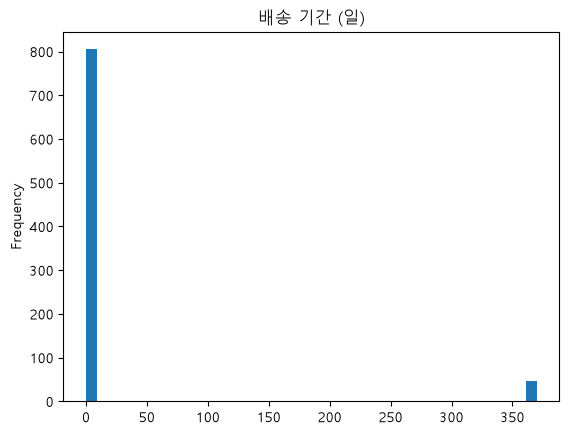

평균 : 22.1  중앙값 : 2.0


In [6]:
ok = ~df["date_error"]
days = (df.loc[ok, "delivery_date"] - df.loc[ok, "shipping_date"]).dt.days

days.plot.hist(bins=40, title="배송 기간 (일)")
plt.show()
print("평균 :", round(days.mean(), 1), " 중앙값 :", days.median())

In [7]:
big = days[days > 300]
print("300일 넘는 줄 :", len(big))
print("일수 범위 :", big.min(), "~", big.max())
df.loc[big.index, ["order_date", "shipping_date", "delivery_date", "status"]].head()

300일 넘는 줄 : 47
일수 범위 : 364.0 ~ 370.0


,order_date,shipping_date,delivery_date,status
11,2023-01-12,2023-01-15,2024-01-15,배송완료
20,2023-01-21,2023-01-23,2024-01-27,배송완료
29,2023-01-30,2023-02-03,2024-02-03,배송완료
41,2023-02-11,2023-02-14,2024-02-17,배송완료
68,2023-03-10,2023-03-14,2024-03-12,배송완료


In [8]:
sub = df.loc[big.index]
year_gap = sub["delivery_date"].dt.year - sub["shipping_date"].dt.year
print(year_gap.value_counts())

1    47
Name: count, dtype: int64


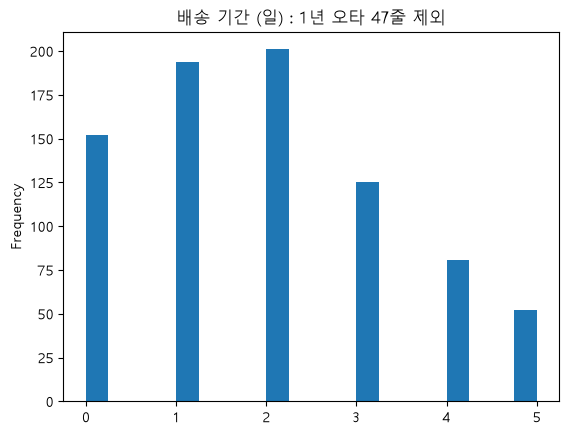

제외한 줄 : 47
평균 : 1.9  중앙값 : 2.0


In [9]:
days_clean = days.drop(big.index)

days_clean.plot.hist(bins=20, title="배송 기간 (일) : 1년 오타 47줄 제외")
plt.show()
print("제외한 줄 :", len(big))
print("평균 :", round(days_clean.mean(), 1), " 중앙값 :", days_clean.median())

**답**
- 배송 기간은 보통 **2일**(중앙값 2.0일)이다. 처음 평균 22.1일이 중앙값 2.0일과 크게 달랐던 이유는 배송 기간이 364~370일인 47줄이 오른쪽 끝에 따로 떨어져 평균을 끌어올렸기 때문이다.
- 이 47줄은 전부 도착 연도가 배송 연도보다 딱 1년 뒤인 **연도 오타**로 보이지만, 1년을 빼면 도착일이 배송일보다 빨라지는 줄도 있어 원래 날짜를 확정할 수 없다. 그래서 날짜는 고치지 않고 배송 기간 계산에서만 제외했고, 제외 후 평균 1.9일 · 중앙값 2.0일로 거의 같아졌다.

## 단계 ⑥ 만족도가 낮을수록 반품이 많은가

satisfaction
1.0     7.6
2.0    12.0
3.0     7.8
4.0     8.7
5.0     6.9
Name: status, dtype: float64


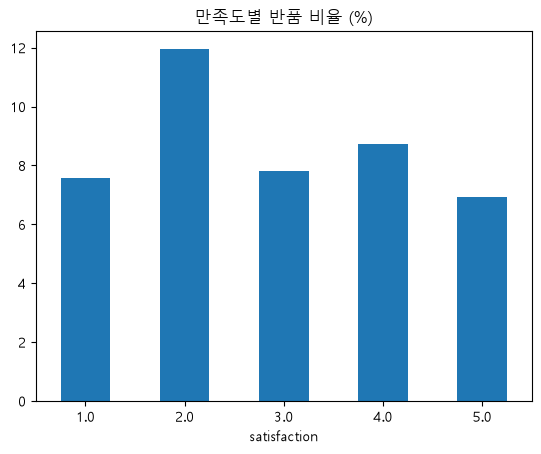

In [10]:
is_return = df["status"] == "반품"
ret = is_return.groupby(df["satisfaction"]).mean() * 100
print(ret.round(1))

ret.plot.bar(title="만족도별 반품 비율 (%)", rot=0)
plt.show()

**답**
- **아니다.** 만족도 1~5별 반품 비율은 7.6% · 12.0% · 7.8% · 8.7% · 6.9%로, 만족도가 낮을수록 꾸준히 늘어나는 모양이 아니다.
- 가장 낮은 만족도 1(7.6%)과 가장 높은 5(6.9%)의 차이는 0.7%p뿐이고, 반품 비율이 가장 높은 것은 만족도 2(12.0%)이다. 이 데이터에서 만족도와 반품 사이에 뚜렷한 관계는 보이지 않는다.

## 단계 ⑦ 카테고리 매출 1위의 이유는 건수 · 단가 · 수량 중 무엇인가

In [11]:
cat = df.groupby("category").agg(
    건수=("total_sales", "count"),
    매출합_억=("total_sales", "sum"),
    평균단가=("unit_price", "mean"),
    평균수량=("quantity", "mean"),
)
cat["매출합_억"] = cat["매출합_억"] / 1e8
cat.sort_values("매출합_억", ascending=False).round(1)

,건수,매출합_억,평균단가,평균수량
category,,,,
가구,213,28.4,257322.9,51.0
식품,210,25.1,255232.9,47.3
전자제품,207,24.7,249651.6,48.0
도서,204,24.5,238500.6,49.5
의류,170,21.8,249447.2,51.6


In [12]:
(cat.loc["가구"] / cat.loc["식품"]).round(3)

건수       1.014
매출합_억    1.131
평균단가     1.008
평균수량     1.079
dtype: float64

**답**
- 매출 1위는 **가구(28.4억)**. 2위 식품(25.1억)과 비교하면 건수(213 vs 210, 1.4%↑)와 평균 단가(25.7만 vs 25.5만 원, 0.8%↑)는 거의 같고, **평균 수량(51.0 vs 47.3개, 약 8%↑)** 에서 가장 차이가 난다.
- 따라서 가구가 1위인 이유는 주문이 많거나 비싸서라기보다 **한 주문당 수량이 많기 때문**이다. 다만 1위와 2위의 매출 차이 자체가 약 1.13배로 크지 않다.